# Actividad 1 · Detección de varios dígitos en una imagen

**Curso:** Técnicas de Aprendizaje Automático · **Semestre:** 2026-2

Este cuaderno parte del `scratchpad.ipynb`, donde ya se entrenó un perceptrón
multicapa sobre MNIST que clasifica correctamente un dígito en una imagen de
28x28. El problema de esta actividad es otro:

> construir un modelo que identifique los números del 1 al 9 teniendo en cuenta
> que puede haber más de un número en la imagen — por ejemplo un 4 y un 5 —
> y que se identifiquen **ambos** (como 4 y 5, no como 45), con una interfaz
> donde se puedan subir las imágenes.

La respuesta tiene tres partes:

1. **El modelo.** Se conserva el MLP del `scratchpad`, con dos correcciones
   (el preprocesamiento y la evaluación) y una añadida (una clase extra).
2. **El detector.** La geometría de la imagen decide *dónde* hay dígitos y el
   modelo decide *qué* son.
3. **La interfaz.** Una página web donde se sube la imagen y se ve el
   resultado.

---

## 0. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

from src import preprocesamiento as prep
from src.datos import cargar_mnist
from src.deteccion import DetectorDeDigitos, Parametros, anotar
from src.modelo import CLASE_FONDO, NUMERO_DE_DIGITOS, cargar_modelo, construir_modelo, preprocesar

SEMILLA = 2026
np.random.seed(SEMILLA)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

print("entorno listo")

entorno listo


## 1. El punto de partida: el MLP del `scratchpad`

La arquitectura del cuaderno original es una perceptrón multicapa de dos
capas ocultas:

$$f(x) = W_3\,\sigma\!\left(W_2\,\sigma(W_1 x + b_1) + b_2\right) + b_3$$

con 784 entradas (los píxeles de la imagen), dos capas de 64 unidades con
activación ReLU y 10 salidas con `softmax`, que dan la distribución de
probabilidad de cada dígito.

Se conserva exactamente esa arquitectura. Lo que había que corregir eran tres
cosas del cuaderno original:

| En el `scratchpad` | Por qué importa | Qué se hace aquí |
|---|---|---|
| Los píxeles entraban en `[0, 255]` | El rango de entrada debería ser `[0, 1]` | Se normalizan |
| No se miraba el conjunto de prueba | La exactitud que se reportaba era de entrenamiento | Se evalúa en prueba, con un 10 % de validación |
| Diez clases, todas dígitos | El detector necesita poder decir "aquí no hay un dígito" | Se añade la clase `fondo` (sección 4) |

In [2]:
modelo = construir_modelo()
modelo.summary()

I0000 00:00:1794494750.795771    8771 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Model: "mnist_mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ entrada (InputLayer)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cp1 (Dense)                     │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cp2 (Dense)                     │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 11)             │           715 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,115 (215.29 KB)

 Trainable params: 55,115 (215.29 KB)

 Non-trainable params: 0 (0.00 B)

### 1.1. Entrenamiento y evaluación

El modelo entrenado queda guardado en `modelos/mnist_mlp.keras`. Si el archivo
no está, se entrena aquí (unos cinco minutos en CPU).

In [3]:
from src.modelo import RUTA_MODELO

if RUTA_MODELO.exists():
    modelo = cargar_modelo()
    print("modelo cargado de", RUTA_MODELO)
else:
    from src.modelo import entrenar

    modelo, metricas = entrenar(verbose=0)
    print("exactitud en prueba: %.4f" % metricas["exactitud_prueba"])

modelo cargado de /home/brayan239/Documents/TAM/ENTREGAS/ACTIVIDAD 1/modelos/mnist_mlp.keras


In [4]:
x_ent, y_ent, x_pru, y_pru = cargar_mnist()
probabilidades = modelo.predict(preprocesar(x_pru), verbose=0)
argmax = probabilidades.argmax(axis=1)

exactitud = float((argmax == y_pru).mean())
rechazados = float((argmax == CLASE_FONDO).mean())
print(f"dígitos bien clasificados: {exactitud:.2%}")
print(f"mandados a la clase 'fondo': {rechazados:.2%}")

W0000 00:00:1794494753.880155    8771 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


dígitos bien clasificados: 93.56%
mandados a la clase 'fondo': 1.26%


### 1.2. Matriz de confusión

Vale la pena ver en qué se confunde el modelo, porque los errores no son
aleatorios: las confusiones típicas de MNIST son 3↔5, 4↔9 y 7↔1.

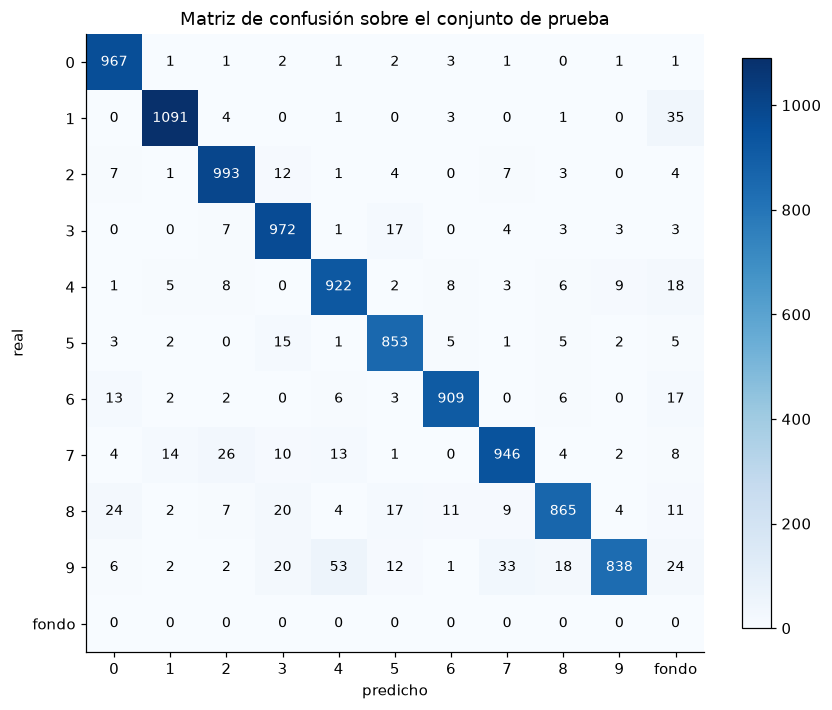

In [5]:
from sklearn.metrics import confusion_matrix

matriz = confusion_matrix(y_pru, argmax, labels=list(range(NUMERO_DE_DIGITOS)) + [CLASE_FONDO])

fig, ax = plt.subplots(figsize=(8, 7))
imagen = ax.imshow(matriz, cmap="Blues")
for i in range(matriz.shape[0]):
    for j in range(matriz.shape[1]):
        color = "white" if matriz[i, j] > matriz.max() / 2 else "black"
        ax.text(j, i, str(matriz[i, j]), ha="center", va="center", color=color, fontsize=9)
ax.set_xticks(range(matriz.shape[1]), [str(c) for c in range(NUMERO_DE_DIGITOS)] + ["fondo"])
ax.set_yticks(range(matriz.shape[0]), [str(c) for c in range(NUMERO_DE_DIGITOS)] + ["fondo"])
ax.set_xlabel("predicho")
ax.set_ylabel("real")
ax.set_title("Matriz de confusión sobre el conjunto de prueba")
fig.colorbar(imagen, ax=ax, shrink=0.8)
plt.tight_layout()
plt.show()

## 2. El problema: una imagen con varios dígitos

El clasificador del `scratchpad` responde a una sola pregunta: *este parche de
28x28 es un 4*. Si se le da una imagen con un 4 y un 5, responde cualquier
cosa: la imagen completa no es ninguno de los dos.

La solución no es inventar un modelo nuevo, sino **separar el problema en dos**:

- la **geometría** de la imagen decide *dónde* hay dígitos;
- el **clasificador** decide *qué* es cada uno de esos dígitos.

La geometría es la parte nueva, y es la que hace que un 4 y un 5 salgan como
dos detecciones y no como un "45".

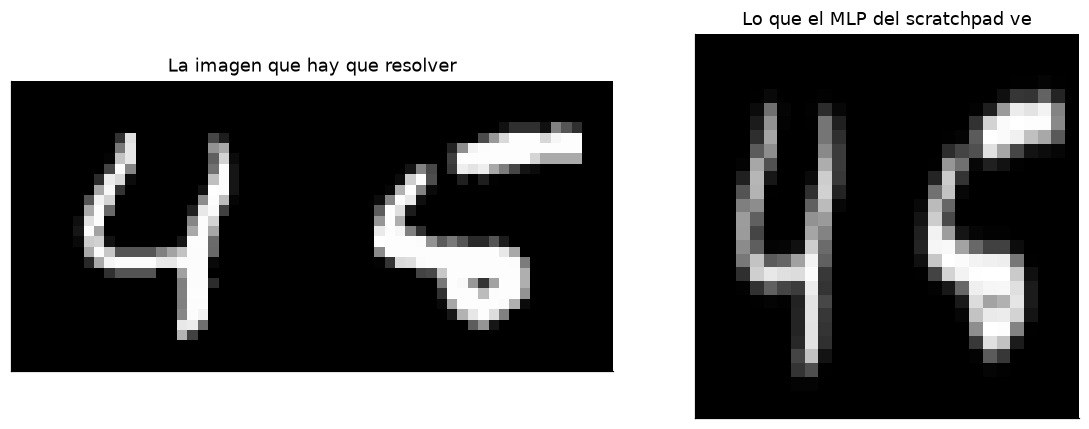

el MLP sobre la imagen completa dice: 10


In [6]:
ejemplo = Image.open(RAIZ / "ejemplos" / "caso_4_y_5.png")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].imshow(ejemplo, cmap="gray")
ax[0].set_title("La imagen que hay que resolver")
ax[1].imshow(ejemplo.resize((28, 28)), cmap="gray")
ax[1].set_title("Lo que el MLP del scratchpad ve")
for eje in ax:
    eje.set_xticks([])
    eje.set_yticks([])
plt.tight_layout()
plt.show()

parche = np.asarray(ejemplo.convert("L").resize((28, 28)), dtype=np.float32) / 255.0
prediccion = modelo.predict(parche.reshape(1, 784), verbose=0)[0]
print("el MLP sobre la imagen completa dice:", int(prediccion.argmax()))

## 3. El detector, etapa por etapa

### 3.1. Preprocesamiento

Tres pasos, todos con una razón:

1. **Escala de grises y rango `[0, 1]`.** El modelo se entrenó con esa escala.
2. **Polaridad.** En MNIST el dígito es claro sobre fondo oscuro; en una foto
   de un papel es al revés. Se decide mirando el marco de la imagen y, si no
   es concluyente, mirando cuál de las dos clases de Otsu es la minoritaria
   (el trazo de un dígito ocupa menos área que el fondo).
3. **Binarización con Otsu.** El umbral que maximiza la varianza entre
   clases, calculado sobre el histograma de 256 niveles.

Después, cada recorte se normaliza al formato de MNIST: se recorta la tinta, se
escala para que quepa en 20x20 respetando la relación de aspecto y se centra
en un lienzo de 28x28. Al final el fondo se deja en **negro** y el trazo en
**blanco**, porque el recorte viene de una foto donde el papel es gris y el
modelo se entrenó con el fondo en negro.

Los bordes grises de los trazos se conservan a propósito: si se pasa todo a
binario, el modelo pierde **1,8 puntos** de exactitud (93,9 % → 92,0 %
medido), porque en MNIST los bordes de los trazos también tienen gris.

> Sobre "consume menos recursos": con un modelo **denso** el fondo en negro no
> ahorra ni una multiplicación, los FLOPs son los mismos. Lo que mejora es que
> la entrada se parezca a la del entrenamiento. Con un modelo convolucional, o
> con una representación dispersa, los ceros sí se pueden aprovechar.

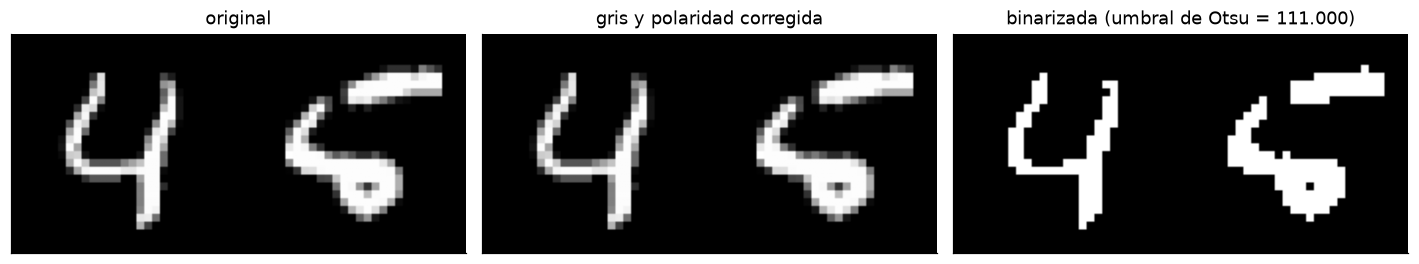

In [7]:
gris = prep.invertir_si_hace_falla(prep.a_escala_grises(ejemplo))
binar = prep.binarizar(gris)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].imshow(ejemplo.convert("L"), cmap="gray")
ax[0].set_title("original")
ax[1].imshow(gris, cmap="gray")
ax[1].set_title("gris y polaridad corregida")
ax[2].imshow(binar, cmap="gray")
ax[2].set_title("binarizada (umbral de Otsu = %.3f)" % prep.umbral_otsu(gris))
for eje in ax:
    eje.set_xticks([])
    eje.set_yticks([])
plt.tight_layout()
plt.show()

### 3.2. Segmentación: dónde puede haber un dígito

La tinta de la imagen se divide en **bloques**, separando por columnas vacías
y por filas vacías.

Es una segmentación rectangular, y por eso funciona: dos dígitos uno al lado
del otro ocupan columnas distintas, así que quedan en bloques distintos
aunque la tinta llegue a tocarse. Cada bloque se revisa después:

- si no es más ancho que alto y no es una mota, **el bloque es un dígito**;
- si es demasiado ancho o alto, puede esconder varios, y entonces se recorre
  con una **ventana deslizante** que busca un dígito por ventana.

La altura del dígito (que define el tamaño de las ventanas) se estima sobre
los bloques y no sobre los componentes conexos: un mismo "5" puede tener
varios componentes, y con los componentes la estimación se quedaba con la
mitad de la altura real.

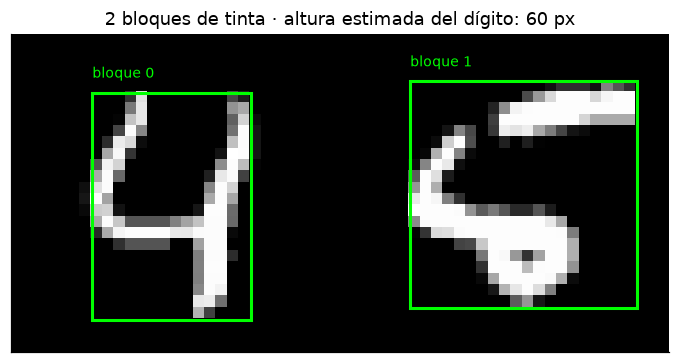

In [8]:
detector = DetectorDeDigitos(modelo, Parametros())
bloques = detector._bloques_de_tinta(binar)
altura = detector._estimar_altura_digito(bloques)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.imshow(gris, cmap="gray")
for i, caja in enumerate(bloques):
    x0, y0, x1, y1 = caja
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="lime", lw=2))
    ax.text(x0, y0 - 4, f"bloque {i}", color="lime", fontsize=9)
ax.set_title(f"{len(bloques)} bloques de tinta · altura estimada del dígito: {altura:.0f} px")
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()

### 3.3. Clasificación y supresión de no máximos

Cada recorte se normaliza y se pasa por el modelo. Los candidatos que se
solapan son el mismo dígito visto de distintas maneras, así que se recorren de
mayor a menor confianza y se conserva el primero de cada grupo.

Ese recorrido es *greedy* y **no transitivo** a propósito. Con un
agrupamiento por componentes conexas, un candidato ancho que abarca dos
dígitos los unía en el mismo grupo y el detector reportaba un solo dígito. Con
el recorrido greedy, el 4 y el 5 se conservan los dos porque no se solapan
entre sí.

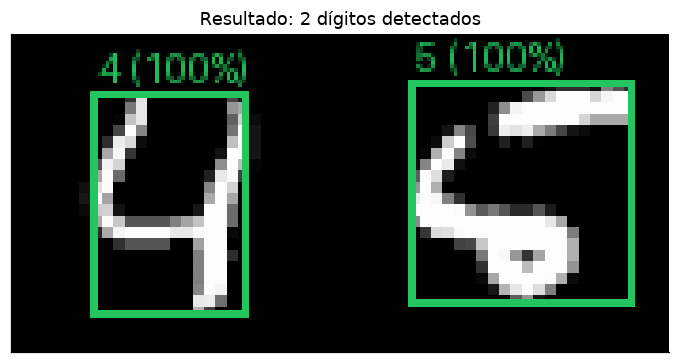

  #1  dígito 4  confianza 100.0%  caja (21, 15, 63, 75)
  #2  dígito 5  confianza 100.0%  caja (105, 12, 165, 72)


In [9]:
detecciones = detector.detectar(ejemplo)

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.imshow(anotar(ejemplo, detecciones))
ax.set_title("Resultado: %d dígitos detectados" % len(detecciones))
ax.set_xticks([])
ax.set_yticks([])
plt.tight_layout()
plt.show()

for i, d in enumerate(detecciones, 1):
    print(f"  #{i}  dígito {d.digito}  confianza {d.confianza:.1%}  caja {d.caja}")

## 4. La clase `fondo`: por qué hace falta

Esta es la parte menos obvia de la actividad, y la que más rendimiento aporta.

Un modelo de diez clases no tiene forma de decir "aquí no hay un dígito". Y
responde con una seguridad aparente: **media barra de un 4 se parece muchísimo
a un 1**. Así que, cuando el detector recorta una ventana que corta el 4 por
la mitad, el modelo responde "1" con el 99,9 % de confianza, y el detector
reporta un 1 donde no hay ningún 1.

La solución es una clase extra, la número 10, llamada `fondo`, entrenada con
los tres tipos de recorte que el detector se encuentra en la práctica:

| Tipo de ejemplo | Qué simula |
|---|---|
| un trozo de un dígito | una ventana que corta el trazo por la mitad |
| dos dígitos en el mismo recorte | una ventana más ancha que un dígito |
| un recorte casi vacío | ruido en la imagen |

Los dígitos positivos y los ejemplos de `fondo` pasan por **el mismo
preprocesamiento y la misma variación aleatoria** (rotación, escala, posición
y ruido). Eso es lo que hace que la clase `fondo` aprenda a distinguir
*completo* de *incompleto* y no simplemente "forma rara" de "forma normal".

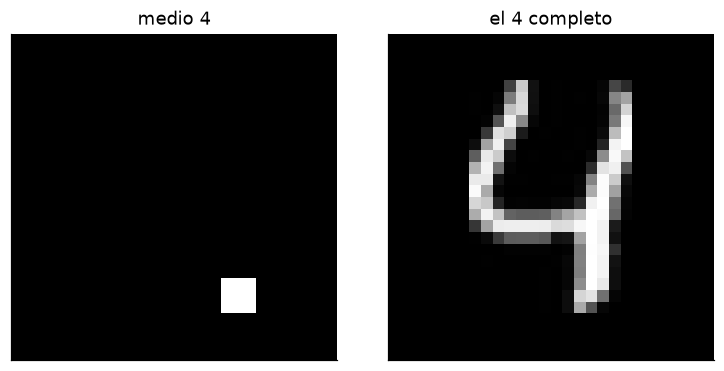

  medio 4      -> 10 (94.4%)   probabilidad de que sea 'fondo': 94.4%
  4 completo   -> 4 (100.0%)   probabilidad de que sea 'fondo': 0.0%


In [10]:
# Un recorte que corta el 4 por la mitad: con diez clases, el modelo diría "1".
recorte = (15, 4, 30, 24)          # la mitad izquierda del 4
parche = prep.normalizar_mnist(gris, recorte)

fig, ax = plt.subplots(1, 2, figsize=(7, 3.4))
ax[0].imshow(parche, cmap="gray")
ax[0].set_title("medio 4")
ax[1].imshow(prep.normalizar_mnist(gris, bloques[0]), cmap="gray")
ax[1].set_title("el 4 completo")
for eje in ax:
    eje.set_xticks([])
    eje.set_yticks([])
plt.tight_layout()
plt.show()

probabilidades = modelo.predict(np.stack([parche.reshape(-1), prep.normalizar_mnist(gris, bloques[0]).reshape(-1)]), verbose=0)
for nombre, fila in zip(["medio 4", "4 completo"], probabilidades):
    print(f"  {nombre:12} -> {int(fila.argmax())} ({fila.max():.1%})   "
          f"probabilidad de que sea 'fondo': {fila[CLASE_FONDO]:.1%}")

### 4.1. Y aun así la geometría manda

Que el modelo tenga la clase `fondo` no significa que se le escuche siempre.
Para los recortes que salen de un bloque de tinta la geometría **ya**
garantiza que hay una sola mancha entera: en ese caso el modelo solo decide
*qué* dígito es, y no hace falta que confirme que hay un dígito.

Para los recortes que salen de una ventana deslizante sí hace falta su
voto: ahí la geometría no garantiza nada.

In [11]:
for nombre in ("caso_4_y_5", "varios_digitos", "cinco_digitos", "un_solo_digito"):
    ruta = RAIZ / "ejemplos" / f"{nombre}.png"
    detecciones = detector.detectar(Image.open(ruta))
    print(f"  {nombre:18} -> {[d.digito for d in detecciones]}")

  caso_4_y_5         -> [4, 5]


  varios_digitos     -> [3, 1, 8, 2]


  cinco_digitos      -> [1, 9, 4, 6, 3]


  un_solo_digito     -> [7]


## 5. Resultados

### 5.1. Sobre el conjunto de prueba

Lo que importa no es solo la exactitud del clasificador, sino cuántas veces
manda a `fondo` un dígito que sí está: esos son los dígitos **perdidos**, que
es el peor error posible para un detector.

In [12]:
# El detector ve el dígito recortado a su tinta y centrado, no el parche crudo.
recortes_prueba = np.stack([
    prep.normalizar_mnist(
        imagen.astype(np.float32) / 255.0,
        prep.caja_de_tinta(prep.binarizar(imagen.astype(np.float32) / 255.0)),
    )
    for imagen in x_pru
])
probabilidades_recorte = modelo.predict(recortes_prueba.reshape(-1, 784), verbose=0)
argmax_recorte = probabilidades_recorte.argmax(axis=1)

print(f"  exactitud (dígito recortado): {float((argmax_recorte == y_pru).mean()):.2%}")
print(f"  perdidos (mandados a fondo):  {float((argmax_recorte == CLASE_FONDO).mean()):.2%}")

W0000 00:00:1794494761.228157    8771 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


  exactitud (dígito recortado): 95.04%
  perdidos (mandados a fondo):  1.11%


### 5.2. Sobre imágenes con varios dígitos

La tabla siguiente compara lo que hay en la imagen con lo que detecta el
modelo. Las imágenes están en `ejemplos/`, y hay dos versiones de cada una: la
de estilo MNIST (dígitos claros sobre fondo oscuro) y la de estilo papel
(dígitos oscuros sobre fondo claro, con ruido, como una foto de una libreta).

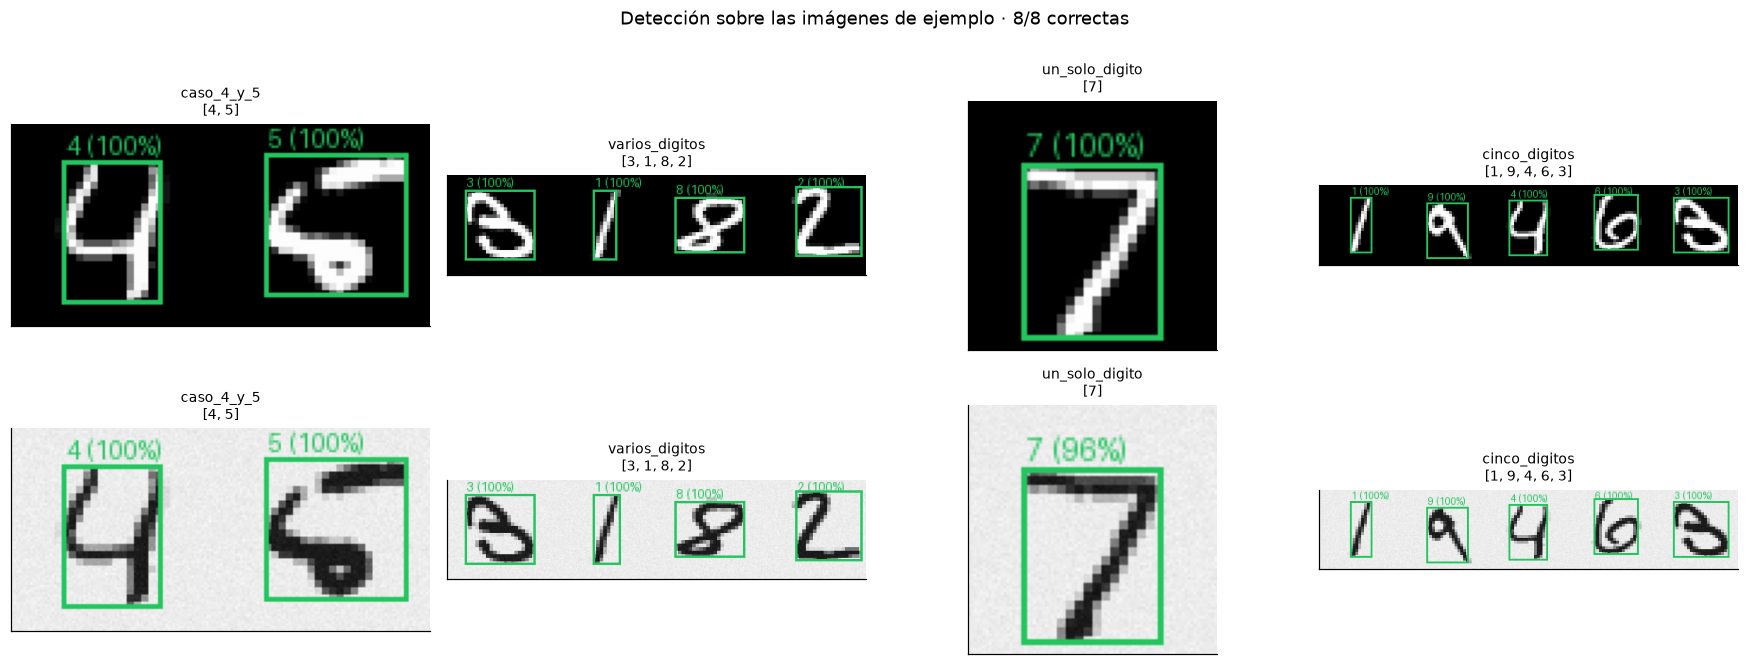

In [13]:
ESPERADOS = {
    "caso_4_y_5": [4, 5],
    "varios_digitos": [3, 1, 8, 2],
    "un_solo_digito": [7],
    "cinco_digitos": [1, 9, 4, 6, 3],
}

fig, axes = plt.subplots(2, 4, figsize=(16, 6))
aciertos = 0
total = 0
for columna, nombre in enumerate(ESPERADOS):
    for fila, sufijo in enumerate(("", "_papel")):
        ruta = RAIZ / "ejemplos" / f"{nombre}{sufijo}.png"
        imagen = Image.open(ruta)
        detecciones = detector.detectar(imagen)
        detectados = [d.digito for d in detecciones]
        total += 1
        aciertos += int(detectados == ESPERADOS[nombre])
        ejes = axes[fila, columna]
        ejes.imshow(anotar(imagen, detecciones))
        ejes.set_title(f"{nombre}\n{detectados}", fontsize=9)
        ejes.set_xticks([])
        ejes.set_yticks([])
plt.suptitle(f"Detección sobre las imágenes de ejemplo · {aciertos}/{total} correctas", y=1.0)
plt.tight_layout()
plt.show()

## 6. La interfaz

Hay dos interfaces sobre el mismo detector.

**Streamlit** (`streamlit run src/app_streamlit.py`): es un dashboard con
indicadores (dígitos detectados, confianza media, tiempo, tamaño de la
imagen), la imagen anotada, la tabla de detecciones y un modo por lotes para
varias imágenes.

**Flask** (`python -m src.app`): más simple, con una API JSON. Recibe la
imagen por un `POST` a `/predecir` y devuelve **una detección por dígito**, más
la imagen con las cajas dibujadas.

```python
detecciones = detector.detectar(imagen)
for d in detecciones:
    print(d.digito, d.confianza, d.caja)
```

### Cambiar de modelo

El dashboard deja elegir el modelo en la barra lateral. Los modelos se leen de
la carpeta `modelos/`, así que cambiar de modelo es dejar el archivo ahí: el
detector se adapta solo a la forma de entrada del modelo (vector de 784 para el
denso, imagen de 28x28 para el convolucional) y la clase `fondo` se toma de la
salida del modelo.

In [14]:
import io
import base64

from src.app import app

with app.test_client() as cliente:
    respuesta = cliente.post(
        "/predecir",
        data={
            "archivo": (io.BytesIO((RAIZ / "ejemplos" / "caso_4_y_5.png").read_bytes()), "caso.png"),
            "umbral": "0.85",
        },
        content_type="multipart/form-data",
    )
    cuerpo = respuesta.get_json()

print("código de respuesta:", respuesta.status_code)
print("dígitos devueltos:", [d["digito"] for d in cuerpo["detecciones"]])
for d in cuerpo["detecciones"]:
    print("   ", d)

código de respuesta: 200
dígitos devueltos: [4, 5]
    {'caja': [21, 15, 63, 75], 'confianza': 1.0, 'digito': 4}
    {'caja': [105, 12, 165, 72], 'confianza': 1.0, 'digito': 5}


## 7. Conclusiones

**Sobre el modelo.** El MLP del `scratchpad` sirve: la arquitectura de dos
capas ocultas de 64 unidades alcanza para clasificar dígitos recortados, y
el preprocesamiento (normalizar a `[0, 1]`) es lo que más mejora el
entrenamiento. Lo que el modelo no tenía, y le hacía falta, es la capacidad de
decir "aquí no hay un dígito".

**Sobre el detector.** Lo que hace que un "45" salga como un 4 y un 5, y no
como un número, no es el modelo: es la **segmentación por bloques de tinta**.
Al dividir la imagen por columnas vacías, dos dígitos uno al lado del otro
quedan separados aunque su tinta se toque, y cada bloque se clasifica por
separado.

**Sobre el orden de las decisiones.** Es la lección más útil de la actividad:
primero la geometría (dónde hay dígitos, y qué forma tienen) y después el
modelo (qué son). Al revés, el modelo recibe recortes que no son dígitos y
responde con una seguridad que no se corresponde con nada.

**Sobre la clase `fondo`.** Es el ajuste que más cambió el comportamiento del
detector, y el que menos obvio es. Un clasificador que solo sabe decir qué es
lo que ve necesita además poder decir que no ve nada.

### Limitaciones

- **Dígitos que se superponen de verdad.** Si el trazo del 4 se cruza con el
  del 5, no hay separación posible por columnas y la ventana deslizante tiene
  que adivinar dónde cortar. Es el caso que peor sale.
- **Un solo dígito por fila.** Los dígitos apilados en vertical se detectan
  como un bloque único.
- **Fondo con textura.** El detector asume que la imagen es el dígito y nada
  más; un fondo con ruido fuerte ensucia las cajas.
- **El modelo es un MLP.** Con una red convolucional el detector mejoraría
  sobre todo en los recortes parciales: las convoluciones aprenden a detectar
  el trazo donde esté, en vez de memorizar la posición exacta de los píxeles.
  Es el primer experimento que haría con más tiempo.